# Lesson 4.7: Plotly Visualization

**Analyst:** John Ko
**Date:** 11/16/26
**Client:** FinFlow (Product Analytics engagement led by Hannah Whitford)
**Notebook purpose:** Produce the visualization deck for Friday's product
leadership review. Single HTML file output with monthly signup trend,
cohort churn pattern, tier comparison, and one supporting chart.

In [1]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

df = pd.read_csv(
    'finflow-enriched-200k.csv',
    parse_dates=['signup_date', 'last_login_date', 'churn_date']
)

cohort_churn = pd.read_csv(
    'cohort-churn-by-signup-month.csv'
)

print(f"Customer data: {df.shape}")
print(f"Cohort churn data: {cohort_churn.shape}")


Customer data: (200000, 22)
Cohort churn data: (25, 4)


## Chart 1: Total signups by plan tier

A simple bar chart. The headline number for the product VP: which tier
has the most customers.

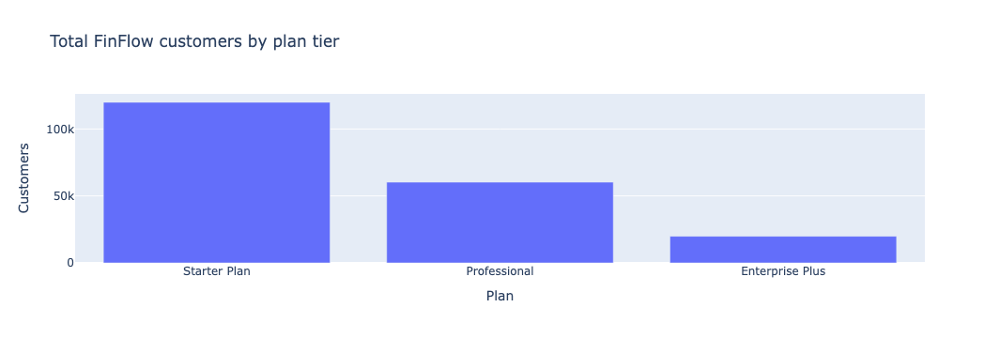

In [2]:
tier_counts = df['marketing_name'].value_counts().reset_index()
tier_counts.columns = ['marketing_name', 'customer_count']

fig_tier_bar = px.bar(
    tier_counts,
    x='marketing_name',
    y='customer_count',
    title='Total FinFlow customers by plan tier',
    labels={'marketing_name': 'Plan', 'customer_count': 'Customers'}
)
fig_tier_bar.update_layout(showlegend=False)
fig_tier_bar.show()

## Chart 2: Monthly signup trend

A line chart of total signups per month. This is the headline trend
question: are signups growing, flat, or declining?

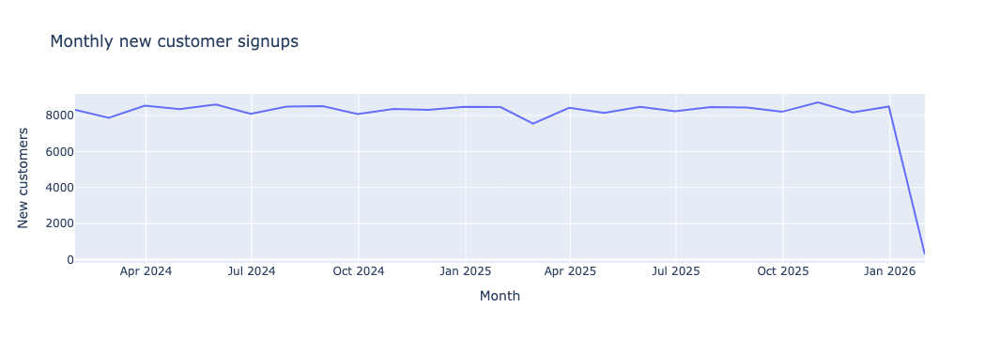

In [3]:
monthly_signups = (df.set_index('signup_date')
                       .resample('ME')
                       .size()
                       .reset_index(name='signups'))
fig_signup_trend= px.line(
    monthly_signups,
    x='signup_date',
    y='signups',
    title='Monthly new customer signups',
    labels={'signup_date': 'Month', 'signups': 'New customers'}
)
fig_signup_trend.update_layout(showlegend=False)
fig_signup_trend.show()

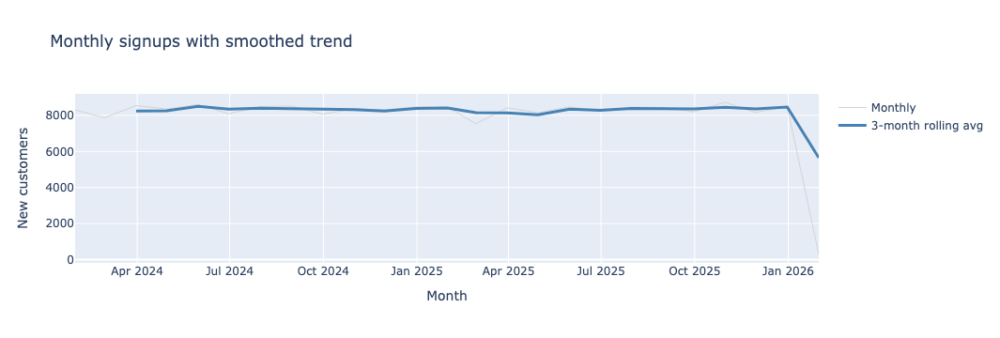

In [4]:
monthly_signups['signups_smoothed'] = monthly_signups['signups'].rolling(window=3).mean()

fig_signup_layered = go.Figure()

fig_signup_layered.add_trace(go.Scatter(
    x=monthly_signups['signup_date'],
    y=monthly_signups['signups'],
    mode='lines',
    name='Monthly',
    line=dict(color='lightgray', width=1)
))

fig_signup_layered.add_trace(go.Scatter(
    x=monthly_signups['signup_date'],
    y=monthly_signups['signups_smoothed'],
    mode='lines',
    name='3-month rolling avg',
    line=dict(color='steelblue', width=3)
))

fig_signup_layered.update_layout(
    title='Monthly signups with smoothed trend',
    xaxis_title='Month',
    yaxis_title='New customers'
)
fig_signup_layered.show()

## Chart 3: Cohort churn pattern

Each cohort's current churn rate, plotted as a line over cohort date.
This is the chart that answers product leadership's "are recent cohorts
churning at different rates than older cohorts?" question.


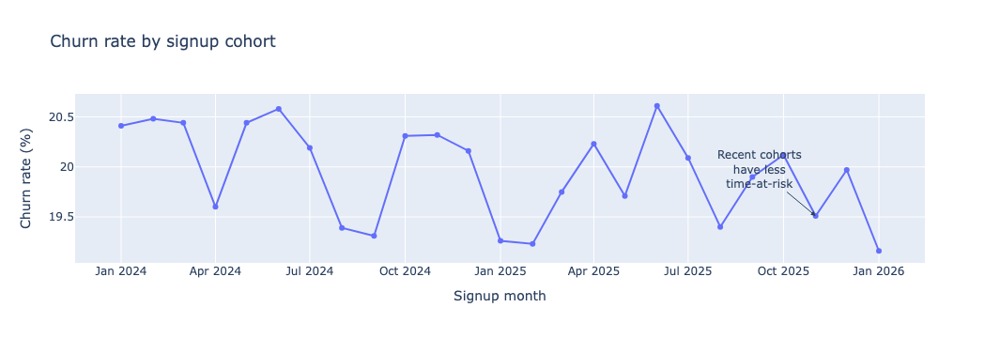

In [5]:
# Make sure signup_cohort is treated as a string for plotting
cohort_churn['signup_cohort_str'] = cohort_churn['signup_cohort'].astype(str)

fig_cohort_churn = px.line(
    cohort_churn,
    x='signup_cohort_str',
    y='churn_rate_pct',
    title='Churn rate by signup cohort',
    labels={
        'signup_cohort_str': 'Signup month',
        'churn_rate_pct': 'Churn rate (%)'
    },
    markers=True
)
fig_cohort_churn.update_layout(showlegend=False)

fig_cohort_churn.add_annotation(
    x=cohort_churn['signup_cohort_str'].iloc[-3],
    y=cohort_churn['churn_rate_pct'].iloc[-3],
    text='Recent cohorts<br>have less<br>time-at-risk',
    showarrow=True,
    arrowhead=2,
    ax=-60,
    ay=-50
)
fig_cohort_churn.show()

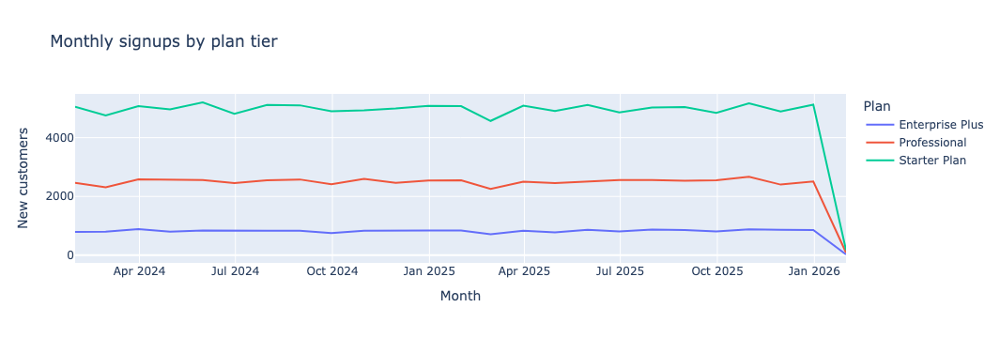

In [6]:
monthly_by_tier = (df.set_index('signup_date')
                     .groupby('marketing_name')
                     .resample('ME')
                     .size()
                     .reset_index(name='signups'))

fig_tier_trend = px.line(
    monthly_by_tier,
    x='signup_date',
    y='signups',
    color='marketing_name',
    title='Monthly signups by plan tier',
    labels={
        'signup_date': 'Month',
        'signups': 'New customers',
        'marketing_name': 'Plan'
    }
)
fig_tier_trend.show()

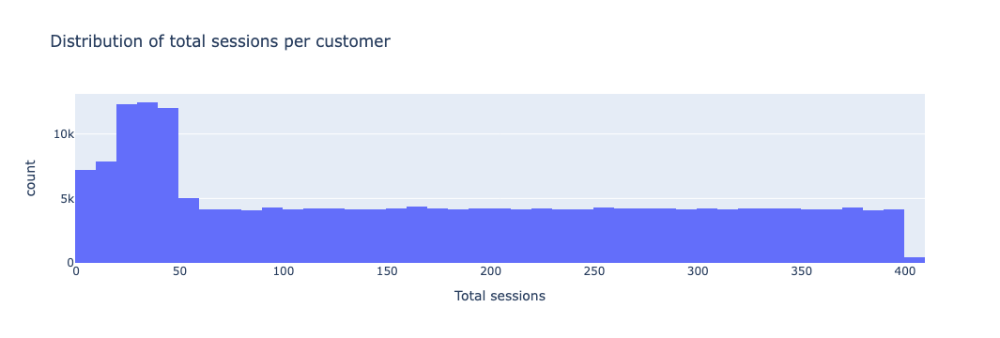

In [7]:
fig_sessions_hist = px.histogram(
    df,
    x='total_sessions',
    nbins=50,
    title='Distribution of total sessions per customer',
    labels={'total_sessions': 'Total sessions', 'count': 'Customers'}
)
fig_sessions_hist.update_layout(showlegend=False)
fig_sessions_hist.show()

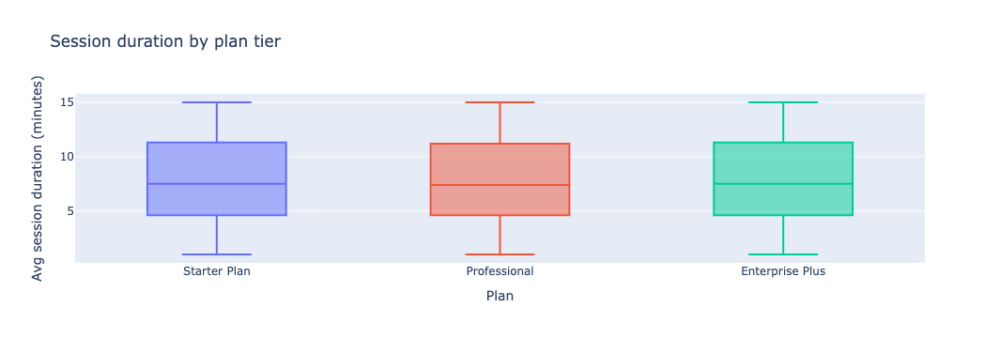

In [8]:
fig_session_box = px.box(
    df,
    x='marketing_name',
    y='avg_session_duration_minutes',
    color='marketing_name',
    title='Session duration by plan tier',
    labels={
        'marketing_name': 'Plan',
        'avg_session_duration_minutes': 'Avg session duration (minutes)'
    }
)
fig_session_box.update_layout(showlegend=False)
fig_session_box.show()

Saved finflow-cohort-deck.html


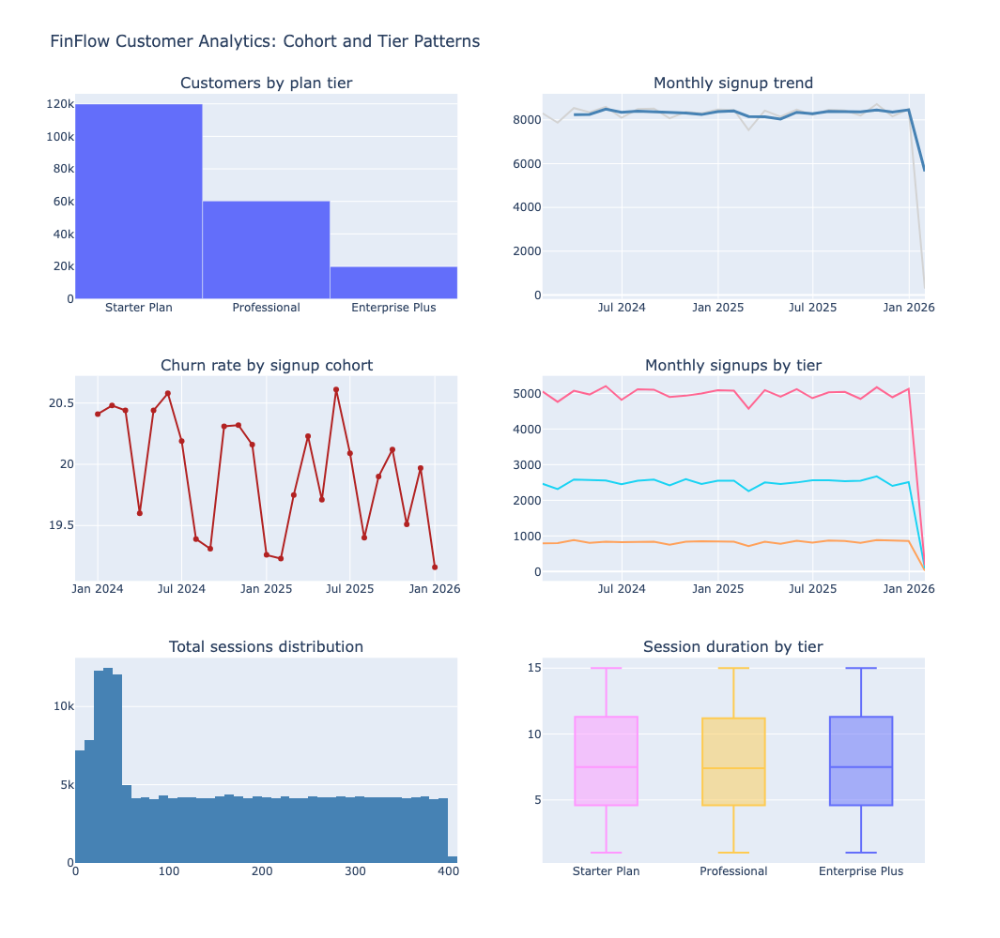

In [11]:
deck = make_subplots(
    rows=3, cols=2,
    subplot_titles=[
        'Customers by plan tier',
        'Monthly signup trend',
        'Churn rate by signup cohort',
        'Monthly signups by tier',
        'Total sessions distribution',
        'Session duration by tier'
    ],
    vertical_spacing=0.10
)

# Chart 1: bar
deck.add_trace(
    go.Bar(x=tier_counts['marketing_name'], y=tier_counts['customer_count'], name='Customers'),
    row=1, col=1
)

# Chart 2: signup trend with smoothing
deck.add_trace(
    go.Scatter(x=monthly_signups['signup_date'], y=monthly_signups['signups'],
               mode='lines', name='Monthly signups', line=dict(color='lightgray')),
    row=1, col=2
)
deck.add_trace(
    go.Scatter(x=monthly_signups['signup_date'], y=monthly_signups['signups_smoothed'],
               mode='lines', name='3-month avg', line=dict(color='steelblue', width=3)),
    row=1, col=2
)

# Chart 3: cohort churn
deck.add_trace(
    go.Scatter(x=cohort_churn['signup_cohort_str'], y=cohort_churn['churn_rate_pct'],
               mode='lines+markers', name='Churn rate', line=dict(color='firebrick')),
    row=2, col=1
)

# Chart 4: tier trend
for tier in monthly_by_tier['marketing_name'].unique():
    tier_data = monthly_by_tier[monthly_by_tier['marketing_name'] == tier]
    deck.add_trace(
        go.Scatter(x=tier_data['signup_date'], y=tier_data['signups'],
                   mode='lines', name=tier),
        row=2, col=2
    )

# Chart 5: histogram
deck.add_trace(
    go.Histogram(x=df['total_sessions'], nbinsx=50, name='Sessions',
                 marker=dict(color='steelblue')),
    row=3, col=1
)

# Chart 6: box plot
for tier in df['marketing_name'].unique():
    deck.add_trace(
        go.Box(y=df[df['marketing_name'] == tier]['avg_session_duration_minutes'],
               name=tier),
        row=3, col=2
    )

deck.update_layout(
    title_text='FinFlow Customer Analytics: Cohort and Tier Patterns',
    height=1000,
    showlegend=False
)

deck.write_html('finflow-cohort-deck.html')
print("Saved finflow-cohort-deck.html")
deck.show()

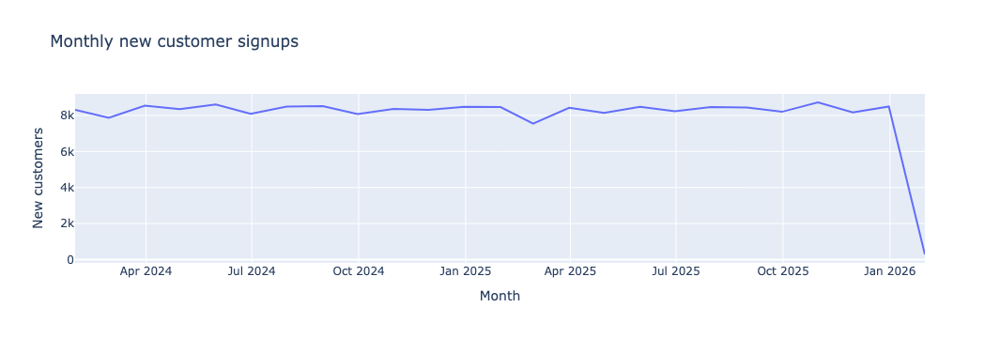

In [10]:
fig_signup_trend.update_layout(yaxis_tickformat='~s')
fig_signup_trend.show()


**AI Use Note:** Used Claude to find the Plotly tick-format syntax for SI
notation. Output was the one-line update_layout call. Verified on the
signup trend chart. Tier 1 disclosure.